# CHALLENGE — Inteligência Artificial & Machine Learning

**Ford FIAP 2026 · Sprint 3 · Desafio 02 — Impulsionando o VIN Share na América do Sul com Soluções Inteligentes**

**Integrantes**
- Guilherme Nunes — RM 558989
- Kaique Zaffarani — RM 556677
- Pedro Josué — RM 554913

## Documentação resumida

| Item | Descrição |
|---|---|
| **Problema** | Baixa retenção no pós-venda, medida pelo VIN Share: a porcentagem de veículos Ford que fazem manutenção na rede oficial |
| **Objetivo** | Prever se o veículo deixará a rede oficial nos próximos 12 meses |
| **Tipo de problema** | Classificação binária supervisionada |
| **Dados** | 20.000 veículos sintéticos com a composição real da frota Ford no Brasil (SENATRAN/RENAVAM, jul/2026) |
| **Modelos** | Regressão Logística, Random Forest, XGBoost e Rede Neural (MLP) |
| **Resultado** | Regressão Logística selecionada: AUC de 0,785 no teste; com ponto de corte de 38%, identifica 79,7% das evasões |
| **Aplicação** | Leads de serviço e de recompra para as concessionárias |

In [1]:
!pip install -q "xgboost>=2.1.4"

import shutil, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
SEED = 42
rng = np.random.default_rng(SEED)   # gerador de números aleatórios com semente fixa: a base é sempre a mesma
GPU = shutil.which('nvidia-smi') is not None   # a GPU T4 é usada pelo XGBoost
CORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
print('GPU disponível:', GPU)

GPU disponível: True


# 1. Compreensão do problema

> **Critérios atendidos:** problema e objetivo · análise das variáveis e dos dados · caracterização do problema de ML

## 1.1 Problema, objetivo e tipo de problema

O **VIN Share** é a porcentagem de veículos Ford que fazem manutenção na rede oficial. Quando o cliente migra para uma oficina independente, a concessionária perde receita de pós-venda e a marca perde o contato que leva à recompra.

O objetivo é estimar, para cada veículo, a probabilidade de **não retornar à rede nos próximos 12 meses**, para que as concessionárias priorizem contatos e ofertas. Trata-se de **classificação binária supervisionada**: o modelo aprende com casos de desfecho conhecido e responde "sim" ou "não" à pergunta "o veículo vai deixar a rede?" (alvo `evadiu_rede_12m`: 1 = evadiu; 0 = retornou). A classificação foi preferida à regressão porque o indicador e a ação da concessionária são definidos por veículo; além disso, a média das probabilidades estima o VIN Share de cada grupo.

## 1.2 Dados: base real e construção da base sintética

Os registros de pós-venda por veículo são privados. Por isso, gerou-se uma base sintética **ancorada na frota real**. Da base oficial do [SENATRAN/RENAVAM](https://dados.transportes.gov.br/dataset/registro-nacional-de-veiculos-automotores-renavam) (julho de 2026, 22,7 milhões de linhas de todas as marcas), foram filtrados os veículos Ford, incluindo os importados, as versões foram agrupadas em modelos e foram mantidos os leves fabricados entre 2012 e 2026: **2.354.576 veículos**. Dessa frota vieram a participação de cada modelo e região e a faixa de anos de cada modelo. Um dado se destaca: **83% da frota são modelos que saíram de linha** (Ka, Fiesta, EcoSport, Focus e Fusion).

Os 20.000 veículos foram gerados por sorteios com semente fixa (`SEED = 42`), o que garante os mesmos resultados a cada execução, em cinco etapas:

1. **Frota real:** modelo, região e ano sorteados com os pesos reais.
2. **Perfil de uso:** tipo de cliente, quilometragem, distância até a concessionária, conectividade, plano de revisão e recall.
3. **Relacionamento com a rede:** revisões, último serviço, NPS e ticket médio, influenciados por um **engajamento oculto** do cliente, que o modelo não enxerga, assim como ocorre com dados reais.
4. **Evasão (alvo):** os fatores de negócio somam uma pontuação de risco, convertida em probabilidade pela função logística e sorteada. Aumentam o risco: estar fora da garantia, ter modelo descontinuado, não fazer revisões, morar longe e gastar acima da referência. Reduzem: revisões frequentes, plano de revisão, ser frotista ou locadora, conectividade, recall pendente e NPS alto.
5. **Problemas de qualidade:** vazios, duplicados, grafias diferentes e valores impossíveis, inseridos para a etapa de preparação.

As distribuições seguem o tipo de dado: lognormal para valores positivos com poucos extremos altos (km, distância e ticket), Poisson para contagens (revisões) e normal para o engajamento e o acaso.

In [2]:
# Etapa 1 — Frota real: modelo, região e ano sorteados com os pesos da frota Ford (SENATRAN)
N = 20_000   # quantidade de veículos da base

# Composição real da frota Ford 2012–2026 (SENATRAN/RENAVAM, jul/2026)
# modelo: (participação na frota em %, ano inicial, ano final, descontinuado no Brasil: 1 = sim)
MODELOS = {
    'Ka':           (37.2, 2014, 2020, 1),
    'Fiesta':       (23.6, 2012, 2015, 1),
    'EcoSport':     (14.6, 2012, 2019, 1),
    'Ranger':       (13.1, 2013, 2025, 0),
    'Focus':        (5.7,  2012, 2017, 1),
    'Fusion':       (1.9,  2013, 2017, 1),
    'Territory':    (1.1,  2020, 2025, 0),
    'Maverick':     (0.6,  2022, 2025, 0),
    'Bronco Sport': (0.4,  2021, 2025, 0),
}
REGIOES = {'Sudeste': 46.4, 'Sul': 25.4, 'Nordeste': 13.6, 'Centro-Oeste': 10.2, 'Norte': 4.4}   # participação (%)

# Sorteio ponderado de modelo e região
pesos = np.array([v[0] for v in MODELOS.values()])
modelo = rng.choice(list(MODELOS), N, p=pesos / pesos.sum())
regiao = rng.choice(list(REGIOES), N, p=np.array(list(REGIOES.values())) / sum(REGIOES.values()))

# Ano de fabricação dentro da faixa real de cada modelo; idade em meses até jun/2026
ano = np.array([rng.integers(MODELOS[m][1], MODELOS[m][2] + 1) for m in modelo])
idade_meses = (2026 - ano) * 12 + rng.integers(0, 12, N)
descontinuado = np.array([MODELOS[m][3] for m in modelo])

# Conferência: participação de cada modelo na frota real (9 modelos) e na base sintética
conferencia = pd.DataFrame({'frota real (%)': pesos / pesos.sum() * 100}, index=list(MODELOS))
conferencia['base sintética (%)'] = pd.Series(modelo).value_counts(normalize=True).reindex(conferencia.index) * 100
display(conferencia.round(1))

,frota real (%),base sintética (%)
Ka,37.9,37.9
Fiesta,24.0,23.8
EcoSport,14.9,15.2
Ranger,13.3,13.3
Focus,5.8,5.8
Fusion,1.9,1.9
Territory,1.1,1.0
Maverick,0.6,0.7
Bronco Sport,0.4,0.5


In [3]:
# Etapa 2 — Perfil de uso do veículo
# Tipo de cliente: 80% pessoa física, 13% frotista, 7% locadora
tipo_cliente = rng.choice(['Pessoa Física', 'Frotista', 'Locadora'], N, p=[0.80, 0.13, 0.07])

# Quilometragem: uso mensal com mediana de 1.200 km (lognormal); frotistas e locadoras rodam 2,5 vezes mais
km_atual = np.round(idade_meses * rng.lognormal(np.log(1200), 0.45, N) * np.where(tipo_cliente == 'Pessoa Física', 1, 2.5), -1)

# Distância até a concessionária: mediana de 18 km, ou de 40 km no Norte e no Centro-Oeste (lognormal)
distancia_km = np.round(rng.lognormal(np.log(np.where(np.isin(regiao, ['Norte', 'Centro-Oeste']), 40, 18)), 0.8), 1)

# Características sim/não (1 = sim)
veiculo_conectado = (rng.random(N) < np.where(ano >= 2020, 0.6, 0.1)).astype(int)   # 60% dos fabricados desde 2020; 10% dos anteriores
plano_revisao = (rng.random(N) < 0.15).astype(int)                                    # 15% têm plano de revisões
recall_pendente = (rng.random(N) < 0.06).astype(int)                                  # 6% têm recall em aberto

In [4]:
# Etapa 3 — Relacionamento com a rede
# Engajamento: característica oculta do cliente, sorteada em torno de 0 (normal)
engajamento = rng.normal(0, 1, N)

# Revisões nos últimos 24 meses (Poisson): mais revisões para clientes engajados e com plano; menos fora da garantia
qtd_revisoes_24m = rng.poisson(np.exp(0.2 + 0.5 * engajamento + 0.5 * plano_revisao - 0.3 * (idade_meses > 36)))
revisou = qtd_revisoes_24m > 0

# Meses desde o último serviço (exponencial): vazio para quem não fez revisão nos últimos 24 meses
meses_ult_servico = np.where(revisou, np.minimum(np.round(rng.exponential(6 * np.exp(-0.4 * engajamento))), np.minimum(23, idade_meses)), np.nan)

# NPS de 0 a 10, maior para clientes engajados; existe só para quem foi atendido, e 65% deles respondem
nps = np.clip(np.round(7.5 + 1.5 * engajamento + rng.normal(0, 1.2, N)), 0, 10)
nps = np.where(revisou & (rng.random(N) < 0.65), nps, np.nan)

# Ticket médio: referência de R$ 800 (R$ 1.500 na Ranger); 1% são serviços de alto valor, 8 vezes a referência
ticket_ref = np.where(modelo == 'Ranger', 1500, 800)
ticket_medio = ticket_ref * rng.lognormal(0, 0.4, N) * np.where(rng.random(N) < 0.01, 8, 1)
ticket_medio = np.where(revisou, np.round(ticket_medio, 2), np.nan)

In [5]:
# Etapa 4 — Evasão (alvo): pontuação de risco → probabilidade → sorteio
# 1) Pontuação de risco: soma dos fatores de negócio
pontuacao = (
    + 1.2 * (idade_meses > 36)                                   # fora da garantia de 3 anos
    + 0.5 * descontinuado                                        # modelo que saiu de linha
    + 0.5 * descontinuado * (idade_meses > 96)                   # descontinuado com mais de 8 anos
    - 0.35 * np.minimum(qtd_revisoes_24m, 4)                     # cada revisão (até 4) reduz o risco
    + 0.9 * ~revisou                                             # nenhuma revisão em 24 meses
    + 0.5 * np.log1p(distancia_km / 20)                          # distância até a concessionária
    + 0.8 * (np.nan_to_num(ticket_medio / ticket_ref) > 1.4)     # gasto 40% acima da referência
    - 0.9 * plano_revisao                                        # plano de revisões pré-pago
    - 0.4 * veiculo_conectado                                    # conectividade
    - 0.3 * recall_pendente                                      # recall é um motivo para voltar
    - 0.15 * np.nan_to_num(nps - 7)                              # satisfação acima ou abaixo de 7
    + 0.3 * np.isnan(nps)                                        # não respondeu à pesquisa
    - 0.5 * (tipo_cliente != 'Pessoa Física')                    # frotistas e locadoras
    - 0.8 * engajamento                                          # característica oculta
    + rng.normal(0, 0.5, N)                                      # acaso
)
pontuacao = pontuacao - pontuacao.mean() + np.log(0.42 / 0.58)   # ajuste da taxa média de evasão para perto de 42%

# 2) Probabilidade: função logística (curva em S)
probabilidade = 1 / (1 + np.exp(-pontuacao))

# 3) Sorteio: 1 = evadiu, 0 = retornou à rede
evadiu = (rng.random(N) < probabilidade).astype(int)

In [6]:
# Etapa 5 — Tabela final e problemas de qualidade inseridos para a Seção 2
df = pd.DataFrame({
    'vin': [f'SYN{i:08d}' for i in range(N)], 'modelo': modelo, 'regiao': regiao, 'tipo_cliente': tipo_cliente,
    'idade_meses': idade_meses, 'km_atual': km_atual, 'distancia_km': distancia_km,
    'veiculo_conectado': veiculo_conectado, 'plano_revisao': plano_revisao, 'recall_pendente': recall_pendente,
    'qtd_revisoes_24m': qtd_revisoes_24m, 'meses_ult_servico': meses_ult_servico, 'nps': nps,
    'ticket_medio': ticket_medio, 'evadiu_rede_12m': evadiu,
})

# Problemas de qualidade inseridos propositalmente
df.loc[rng.random(N) < 0.05, 'km_atual'] = np.nan                                          # 5% sem quilometragem
df.loc[rng.random(N) < 0.03, 'distancia_km'] = np.nan                                      # 3% sem distância
i = rng.random(N) < 0.005; df.loc[i, 'km_atual'] = -df.loc[i, 'km_atual']                  # 0,5% com sinal trocado
df.loc[rng.random(N) < 0.003, 'km_atual'] = 9_999_999                                      # 0,3% com valor impossível
i = rng.random(N) < 0.04; df.loc[i, 'tipo_cliente'] = df.loc[i, 'tipo_cliente'].str.upper()        # 4% em maiúsculas
i = rng.random(N) < 0.03; df.loc[i, 'regiao'] = df.loc[i, 'regiao'].str.lower() + ' '              # 3% em minúsculas com espaço
df = pd.concat([df, df.sample(150, random_state=SEED)], ignore_index=True)                # 150 registros repetidos
df.head()

,vin,modelo,regiao,tipo_cliente,idade_meses,km_atual,distancia_km,veiculo_conectado,plano_revisao,recall_pendente,qtd_revisoes_24m,meses_ult_servico,nps,ticket_medio,evadiu_rede_12m
0,SYN00000000,Ranger,Nordeste,Frotista,116,404250.0,5.3,0,1,0,1,13.0,NaN,1456.09,0
1,SYN00000001,Fiesta,Norte,Pessoa Física,166,193940.0,36.8,0,0,0,6,4.0,10.0,863.70,0
2,SYN00000002,Ranger,Sudeste,Frotista,162,522350.0,30.2,0,0,0,0,NaN,NaN,NaN,0
3,SYN00000003,EcoSport,Sudeste,Locadora,172,440740.0,11.7,0,1,0,2,0.0,NaN,470.53,1
4,SYN00000004,Ka,Sul,Pessoa Física,132,109840.0,14.4,0,0,0,1,0.0,NaN,510.35,0


## 1.3 Dicionário de variáveis

| Variável | Descrição |
|---|---|
| `vin` | Código fictício do veículo |
| `modelo`, `regiao`, `tipo_cliente` | Modelo Ford, região e tipo de cliente (pessoa física, frotista ou locadora) |
| `idade_meses`, `km_atual` | Idade do veículo e quilometragem |
| `distancia_km` | Distância até a concessionária |
| `veiculo_conectado`, `plano_revisao`, `recall_pendente` | Conectividade FordPass, plano de revisões pré-pago e recall em aberto (1 = sim) |
| `qtd_revisoes_24m` | Passagens pela rede nos últimos 24 meses |
| `meses_ult_servico` | Meses desde o último serviço na rede (vazio = nenhum em 24 meses) |
| `nps` | Nota de 0 a 10 dada ao último atendimento na pesquisa de satisfação (*Net Promoter Score*); vazio = não respondeu |
| `ticket_medio` | Gasto médio por serviço na rede, em R$ |
| **`evadiu_rede_12m`** | **Alvo: 1 = não retornou à rede em 12 meses** |

## 1.4 Análise inicial do VIN Share

Em cada grupo, o VIN Share é a porcentagem dos veículos **daquele grupo** que retornaram à rede. A linha tracejada marca a média geral.

Registros: 20,150 | Taxa de evasão: 45.3% | VIN Share geral: 54.7%


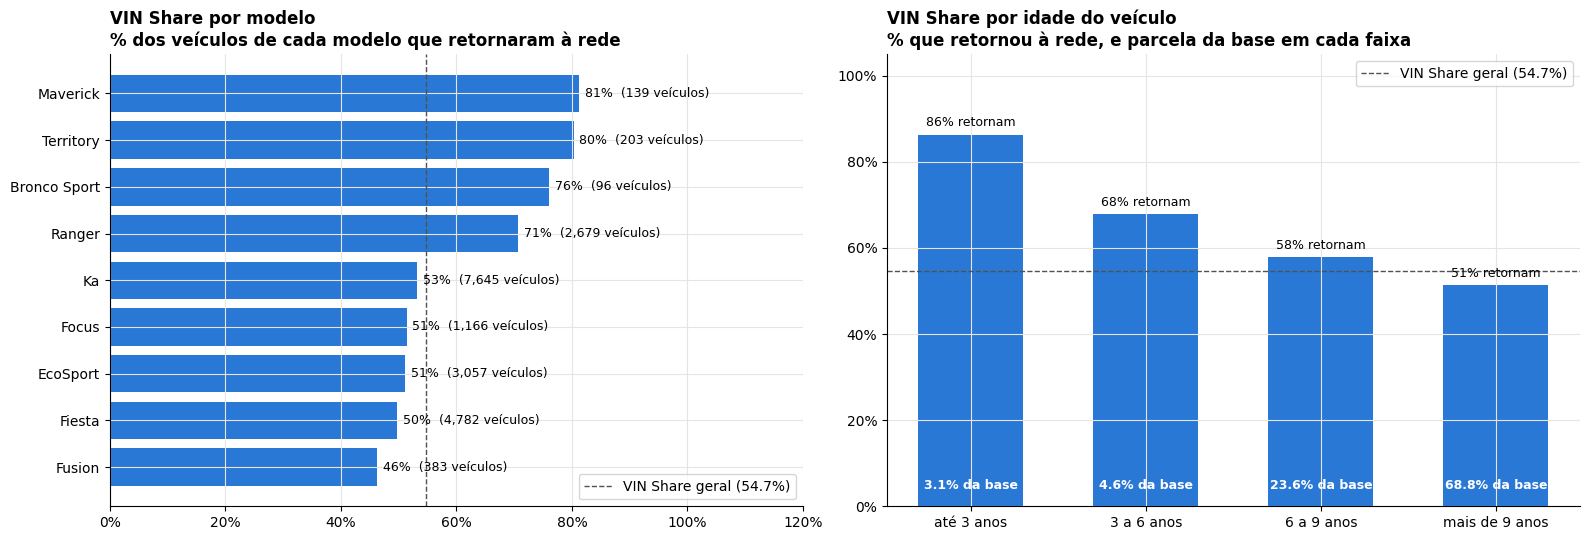

In [7]:
vin_share_geral = 1 - df['evadiu_rede_12m'].mean()
print(f'Registros: {len(df):,} | Taxa de evasão: {df["evadiu_rede_12m"].mean():.1%} | VIN Share geral: {vin_share_geral:.1%}')

por_modelo = df.groupby('modelo')['evadiu_rede_12m'].agg(evasao='mean', veiculos='size')
por_modelo['vin_share'] = 1 - por_modelo['evasao']
por_modelo = por_modelo.sort_values('vin_share')

faixa = pd.cut(df['idade_meses'] / 12, [0, 3, 6, 9, 15], labels=['até 3 anos', '3 a 6 anos', '6 a 9 anos', 'mais de 9 anos'])
por_idade = df.groupby(faixa, observed=True)['evadiu_rede_12m'].agg(evasao='mean', veiculos='size')
por_idade['vin_share'] = 1 - por_idade['evasao']
por_idade['parcela_da_base'] = por_idade['veiculos'] / len(df)

fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))
eixos[0].barh(por_modelo.index, por_modelo['vin_share'], color=CORES[0])
eixos[0].axvline(vin_share_geral, color='#52514e', linestyle='--', linewidth=1, label=f'VIN Share geral ({vin_share_geral:.1%})')
for posicao, (vs, n) in enumerate(zip(por_modelo['vin_share'], por_modelo['veiculos'])):
    eixos[0].text(vs + 0.01, posicao, f'{vs:.0%}  ({n:,} veículos)', va='center', fontsize=9)
eixos[0].set_xlim(0, 1.2)
eixos[0].xaxis.set_major_formatter('{x:.0%}')
eixos[0].legend(loc='lower right')
eixos[0].set_title('VIN Share por modelo\n% dos veículos de cada modelo que retornaram à rede')

barras = eixos[1].bar(por_idade.index.astype(str), por_idade['vin_share'], color=CORES[0], width=0.6)
eixos[1].axhline(vin_share_geral, color='#52514e', linestyle='--', linewidth=1, label=f'VIN Share geral ({vin_share_geral:.1%})')
for barra, vs, parcela in zip(barras, por_idade['vin_share'], por_idade['parcela_da_base']):
    centro = barra.get_x() + barra.get_width() / 2
    eixos[1].text(centro, vs + 0.02, f'{vs:.0%} retornam', ha='center', fontsize=9)
    eixos[1].text(centro, 0.04, f'{parcela:.1%} da base', ha='center', fontsize=9, color='white', fontweight='bold')
eixos[1].set_ylim(0, 1.05)
eixos[1].yaxis.set_major_formatter('{x:.0%}')
eixos[1].legend(loc='upper right')
eixos[1].set_title('VIN Share por idade do veículo\n% que retornou à rede, e parcela da base em cada faixa')
plt.tight_layout()
plt.show()

- A base tem 45,3% de evasão, ou seja, **VIN Share de 54,7%**.
- Os modelos atuais retêm mais (Maverick 81%, Territory 80%), mas são poucos. Os descontinuados, que formam a maior parte da frota, ficam entre 46% (Fusion) e 53% (Ka).
- Só 3,1% dos veículos têm até 3 anos (ainda na garantia), e 86% deles retornam. Acima de 9 anos estão 69% da base, com retorno de apenas 51%.
- **A evasão se concentra onde está a maior parte da frota: veículos antigos, fora da garantia e de modelos descontinuados.**

# 2. Preparação dos dados

> **Critérios atendidos:** ausentes, inconsistências e outliers · criação e seleção de variáveis · transformação e padronização · divisão em treino e teste

## 2.1 Qualidade dos dados: diagnóstico e tratamento

Verificaram-se duplicados, campos vazios, grafias diferentes e valores impossíveis.

In [8]:
print('Registros duplicados:', df.duplicated().sum())
ausentes = df.isna().sum()
display(pd.DataFrame({'ausentes': ausentes, '% ausentes': (ausentes / len(df) * 100).round(1)})[ausentes > 0])
print('Categorias de tipo_cliente:', sorted(df['tipo_cliente'].unique()))
print('Categorias de regiao:', sorted(df['regiao'].unique()))
display(df[['km_atual', 'distancia_km', 'ticket_medio']].describe().round(1))

Registros duplicados: 150


,ausentes,% ausentes
km_atual,1005,5.0
distancia_km,592,2.9
meses_ult_servico,7533,37.4
nps,11857,58.8
ticket_medio,7533,37.4


Categorias de tipo_cliente: ['FROTISTA', 'Frotista', 'LOCADORA', 'Locadora', 'PESSOA FÍSICA', 'Pessoa Física']
Categorias de regiao: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul', 'centro-oeste ', 'nordeste ', 'norte ', 'sudeste ', 'sul ']


,km_atual,distancia_km,ticket_medio
count,19145.0,19558.0,12617.0
mean,244232.0,29.4,1031.1
std,591059.6,32.0,875.6
min,-1057690.0,0.9,165.1
25%,107660.0,11.3,640.4
50%,166310.0,19.8,862.0
75%,259540.0,35.4,1179.7
max,9999999.0,659.7,21604.7


| Problema encontrado | Tratamento |
|---|---|
| 150 registros duplicados | Removidos |
| `tipo_cliente` e `regiao` com grafias diferentes (ex.: "Sul" e "sul ") | Padronizados |
| 278 quilometragens negativas ou acima de 1 milhão | Convertidas em vazio |
| Vazios por falha de registro em `km_atual` (5,0%) e `distancia_km` (2,9%) | Preenchidos pela mediana do treino (Seção 2.4) |
| Vazios com significado em `nps` (58,8%), `ticket_medio` e `meses_ult_servico` (37,4%): cliente não respondeu ou não foi atendido | Mantidos e representados por variáveis indicadoras (Seção 2.3) |

In [9]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
df['regiao'] = df['regiao'].str.strip().str.title()
df['tipo_cliente'] = df['tipo_cliente'].str.strip().str.title()
km_invalido = (df['km_atual'] < 0) | (df['km_atual'] > 1_000_000)
df.loc[km_invalido, 'km_atual'] = np.nan

print(f'Duplicados removidos: {antes - len(df)}')
print(f'Quilometragens inválidas convertidas em ausentes: {km_invalido.sum()}')
print('Categorias após padronização:', sorted(df['regiao'].unique()), sorted(df['tipo_cliente'].unique()))

Duplicados removidos: 150
Quilometragens inválidas convertidas em ausentes: 278
Categorias após padronização: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul'] ['Frotista', 'Locadora', 'Pessoa Física']


## 2.2 Outliers

Pelo critério do intervalo interquartil (IQR), que aponta valores muito distantes da faixa central dos dados, foram encontrados 1.204 outliers em `km_atual`, 1.399 em `distancia_km` e 642 em `ticket_medio`. Como os valores impossíveis já foram removidos, esses extremos são genuínos (uso intenso, clientes distantes e reparos caros) e foram mantidos. Para reduzir a sua influência, aplica-se a transformação logarítmica (`log1p`) no pipeline da Seção 2.4: na distância, o maior valor passa de 33 para cerca de 2 vezes a mediana. Diferentemente da padronização, que só muda a escala, o log muda a forma da distribuição.

,outliers (IQR),mediana,máximo
km_atual,1204,165800.0,997160.0
distancia_km,1399,19.8,659.7
ticket_medio,642,861.3,21604.7


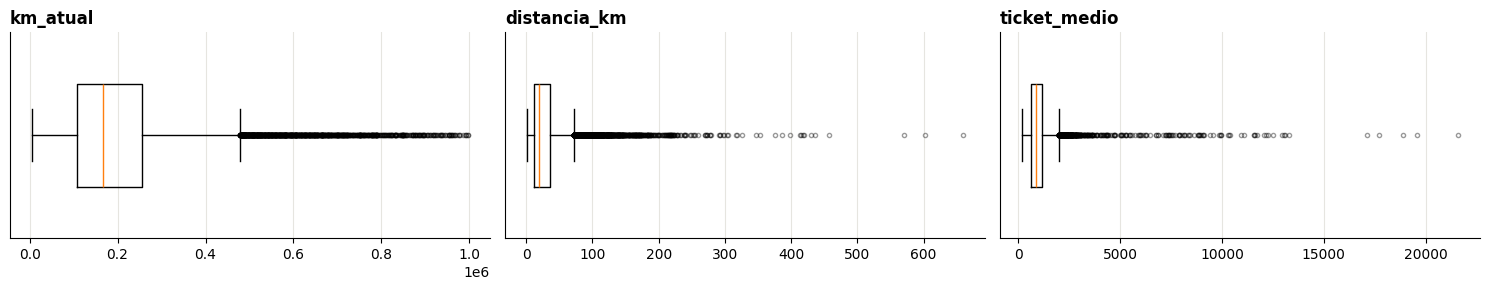

,máximo ÷ mediana (original),máximo ÷ mediana (após log1p)
km_atual,6.0,1.1
distancia_km,33.3,2.1
ticket_medio,25.1,1.5


In [10]:
def contar_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return ((serie < q1 - 1.5 * (q3 - q1)) | (serie > q3 + 1.5 * (q3 - q1))).sum()

colunas = ['km_atual', 'distancia_km', 'ticket_medio']
display(pd.DataFrame({'outliers (IQR)': [contar_outliers(df[c].dropna()) for c in colunas],
                      'mediana': [df[c].median() for c in colunas], 'máximo': [df[c].max() for c in colunas]},
                     index=colunas).round(1))

fig, eixos = plt.subplots(1, 3, figsize=(15, 3))
for eixo, coluna in zip(eixos, colunas):
    eixo.boxplot(df[coluna].dropna(), vert=False, widths=0.5, flierprops={'markersize': 3, 'alpha': 0.4})
    eixo.set_title(coluna)
    eixo.set_yticks([])
plt.tight_layout()
plt.show()

# Ilustração do efeito do log1p (aplicado no pipeline da Seção 2.4): quantas vezes o maior valor supera a mediana
display(pd.DataFrame({
    'máximo ÷ mediana (original)': [df[c].max() / df[c].median() for c in colunas],
    'máximo ÷ mediana (após log1p)': [np.log1p(df[c]).max() / np.log1p(df[c]).median() for c in colunas],
}, index=colunas).round(1))

## 2.3 Criação e seleção de variáveis

Foram criadas variáveis a partir de hipóteses de negócio, verificadas pela correlação abaixo e confirmadas na Seção 4:

| Variável | Regra | Hipótese |
|---|---|---|
| `em_garantia` | idade ≤ 36 meses | A garantia faz o cliente voltar |
| `km_por_mes` | km ÷ idade | Quem roda mais precisa de mais serviços |
| `nunca_revisou` | nenhuma revisão em 24 meses | O vínculo com a rede foi perdido |
| `respondeu_nps` | NPS preenchido | Cliente engajado |
| `modelo_descontinuado` | fora de linha no Brasil | Menor vínculo com a marca |

Quando não houve serviço, `meses_ult_servico` recebe a idade do veículo. Foram removidas `vin` (identificador) e `km_atual`, cuja informação já está em idade × km por mês.

Correlação idade_meses × km_atual: 0.38 → km_atual removida


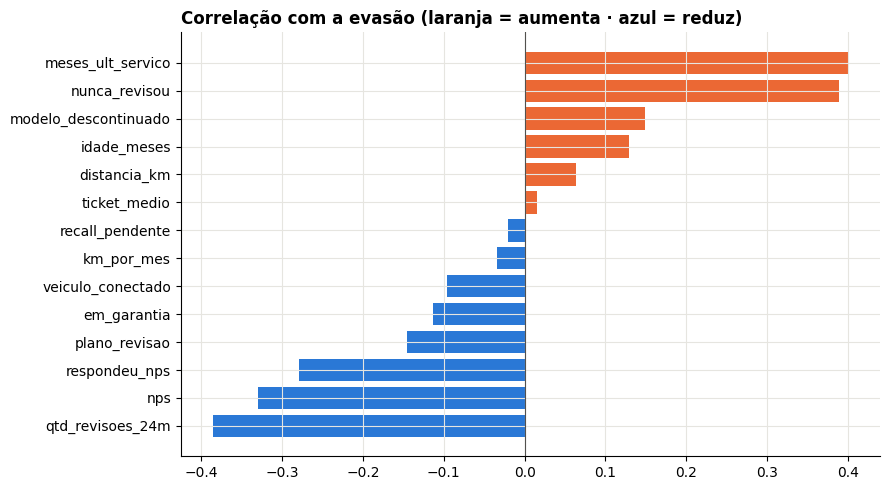

In [11]:
df['em_garantia'] = (df['idade_meses'] <= 36).astype(int)
df['km_por_mes'] = df['km_atual'] / df['idade_meses'].clip(lower=1)
df['nunca_revisou'] = (df['qtd_revisoes_24m'] == 0).astype(int)
df['respondeu_nps'] = df['nps'].notna().astype(int)
df['modelo_descontinuado'] = df['modelo'].map(lambda m: MODELOS[m][3])
df['meses_ult_servico'] = df['meses_ult_servico'].fillna(df['idade_meses'])

NUM_LOG = ['km_por_mes', 'distancia_km', 'ticket_medio']                 # assimétricas: recebem log1p
NUM = ['idade_meses', 'qtd_revisoes_24m', 'meses_ult_servico', 'nps']
BIN = ['em_garantia', 'nunca_revisou', 'respondeu_nps', 'modelo_descontinuado',
       'veiculo_conectado', 'plano_revisao', 'recall_pendente']
CAT = ['modelo', 'regiao', 'tipo_cliente']
ALVO = 'evadiu_rede_12m'

print(f"Correlação idade_meses × km_atual: {df['idade_meses'].corr(df['km_atual']):.2f} → km_atual removida")
correlacao = df[NUM_LOG + NUM + BIN].corrwith(df[ALVO]).sort_values()
fig, eixo = plt.subplots(figsize=(9, 5))
eixo.barh(correlacao.index, correlacao.values, color=[CORES[1] if v > 0 else CORES[0] for v in correlacao.values])
eixo.axvline(0, color='#52514e', linewidth=0.8)
eixo.set_title('Correlação com a evasão (laranja = aumenta · azul = reduz)')
plt.tight_layout()
plt.show()

Na correlação, que vai de −1 a 1, `nunca_revisou` (+0,39) e `respondeu_nps` (−0,28) confirmaram as hipóteses; `modelo_descontinuado` (+0,15) e `em_garantia` (−0,11) tiveram relação fraca, e `km_por_mes` (−0,03), quase nula. As relações mais fortes vieram do histórico com a rede: `meses_ult_servico` (+0,40), `qtd_revisoes_24m` (−0,39) e `nps` (−0,33). Todas as variáveis foram mantidas, pois as pouco úteis recebem pouco peso nos modelos.

## 2.4 Transformação e divisão em treino e teste

Os dados foram divididos em treino (80%, 16.000 registros) e teste (20%, 4.000), com a mesma taxa de evasão (45,3%) nos dois. As transformações são ajustadas só no treino, para que nenhuma informação do teste vaze para o modelo:

- **Numéricas:** preenchimento pela mediana, `log1p` nas assimétricas (km por mês, distância e ticket) e padronização (média 0 e desvio 1), para que nenhuma variável domine as demais pela escala.
- **Categóricas:** *one-hot*, que transforma cada categoria em uma coluna 0/1.
- **Binárias:** mantidas como 0/1.

As 17 variáveis resultam em 31 colunas.

In [12]:
X = df[NUM_LOG + NUM + BIN + CAT]
y = df[ALVO]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

preprocessador = ColumnTransformer([
    ('num_log', Pipeline([('imputar', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p)),
                          ('padronizar', StandardScaler())]), NUM_LOG),
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('padronizar', StandardScaler())]), NUM),
    ('bin', 'passthrough', BIN),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT),
])

X_transformado = preprocessador.fit_transform(X_treino)
print(f'Treino: {len(X_treino):,} registros | Teste: {len(X_teste):,} registros')
print(f'Taxa de evasão — treino: {y_treino.mean():.1%} | teste: {y_teste.mean():.1%}')
print(f'{X_treino.shape[1]} variáveis de entrada → {X_transformado.shape[1]} colunas após a transformação')
display(pd.DataFrame(X_transformado[:, :7], columns=NUM_LOG + NUM).agg(['mean', 'std']).round(2))

Treino: 16,000 registros | Teste: 4,000 registros
Taxa de evasão — treino: 45.3% | teste: 45.3%
17 variáveis de entrada → 31 colunas após a transformação


,km_por_mes,distancia_km,ticket_medio,idade_meses,qtd_revisoes_24m,meses_ult_servico,nps
mean,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


# 3. Desenvolvimento dos modelos

> **Critérios atendidos:** algoritmos de ML e rede neural · justificativa · treinamento · ajuste de parâmetros · comparação de configurações e algoritmos

## 3.1 Algoritmos, hiperparâmetros e validação cruzada

| Algoritmo | Por que foi escolhido | Hiperparâmetros testados |
|---|---|---|
| **Regressão Logística** | Linear e interpretável; serve de referência (*baseline*) | `C`: 0,01; 0,1; 1; 10 |
| **Random Forest** | Várias árvores de decisão que votam; capta relações não lineares | profundidade (6, 12 ou livre); mínimo de casos por folha (1 ou 20) |
| **XGBoost** | Árvores em sequência, cada uma corrigindo a anterior; forte em dados tabulares e usa a GPU T4 | nº de árvores (200 ou 400); profundidade (3 ou 5); taxa de aprendizado (0,05 ou 0,1) |
| **Rede Neural (MLP)** | Camadas de neurônios artificiais para relações complexas | camadas (32 ou 64-32); regularização `alpha` (0,0001 ou 0,01) |

Hiperparâmetros são configurações definidas antes do treino. As 22 combinações foram testadas com `GridSearchCV` e **validação cruzada em 3 partes**: o treino é dividido em três, o modelo treina em duas e é avaliado na terceira, em rodízio. Escolhe-se o modelo de maior AUC média; o teste fica reservado para a avaliação final.

In [13]:
ALGORITMOS = {
    'Regressão Logística': (LogisticRegression(max_iter=1000),
                            {'modelo__C': [0.01, 0.1, 1, 10]}),
    'Random Forest': (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {'modelo__n_estimators': [200], 'modelo__max_depth': [6, 12, None], 'modelo__min_samples_leaf': [1, 20]}),
    'XGBoost': (XGBClassifier(tree_method='hist', device='cuda' if GPU else 'cpu', eval_metric='logloss', random_state=SEED),
                {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [3, 5], 'modelo__learning_rate': [0.05, 0.1]}),
    'Rede Neural (MLP)': (MLPClassifier(max_iter=300, early_stopping=True, random_state=SEED),
                          {'modelo__hidden_layer_sizes': [(32,), (64, 32)], 'modelo__alpha': [0.0001, 0.01]}),
}

resultados = {}
for nome, (estimador, grade) in ALGORITMOS.items():
    inicio = time.time()
    busca = GridSearchCV(Pipeline([('prep', preprocessador), ('modelo', estimador)]), grade, cv=3, scoring='roc_auc')
    busca.fit(X_treino, y_treino)
    resultados[nome] = busca
    print(f'{nome:<20} AUC (validação cruzada) = {busca.best_score_:.3f} | {time.time() - inicio:.0f}s')

comparacao = pd.DataFrame({
    nome: {'AUC média (CV)': b.best_score_, 'Desvio (CV)': b.cv_results_['std_test_score'][b.best_index_],
           'Configurações testadas': len(b.cv_results_['params']),
           'Melhores hiperparâmetros': {k.replace('modelo__', ''): v for k, v in b.best_params_.items()}}
    for nome, b in resultados.items()}).T.sort_values('AUC média (CV)', ascending=False)
MELHOR = comparacao.index[0]
display(comparacao)
print('Modelo escolhido (maior AUC na validação cruzada):', MELHOR)

Regressão Logística  AUC (validação cruzada) = 0.795 | 3s
Random Forest        AUC (validação cruzada) = 0.792 | 58s
XGBoost              AUC (validação cruzada) = 0.795 | 11s
Rede Neural (MLP)    AUC (validação cruzada) = 0.792 | 13s


,AUC média (CV),Desvio (CV),Configurações testadas,Melhores hiperparâmetros
Regressão Logística,0.794977,0.002896,4,{'C': 0.1}
XGBoost,0.794654,0.004533,8,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
Random Forest,0.792189,0.004942,6,"{'max_depth': 12, 'min_samples_leaf': 20, 'n_e..."
Rede Neural (MLP),0.791652,0.003317,4,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,)}"


Modelo escolhido (maior AUC na validação cruzada): Regressão Logística


## 3.2 Resultado e ajuste do modelo escolhido

Os quatro algoritmos empataram na prática (AUC entre 0,792 e 0,795). A **Regressão Logística** teve a maior média (0,795 ± 0,003) e foi a escolhida, além de ser a mais rápida. Isso indica que, nesta base, os fatores de risco atuam de forma aditiva, sem interações que justifiquem modelos mais complexos.

**Hiperparâmetro `C`:** controla a regularização, uma penalidade sobre pesos grandes que evita que o modelo "decore" o treino (sobreajuste). A relação é inversa: C pequeno significa penalidade forte e modelo mais conservador; C grande, penalidade fraca e mais risco de sobreajuste. O melhor foi **C = 0,1**, com penalidade 10 vezes maior que o padrão (C = 1). A AUC variou menos de 0,001 entre os valores testados, o que mostra um modelo estável: com 16.000 exemplos para 31 colunas, há dados suficientes para dispensar um freio forte.

In [14]:
cv = pd.DataFrame(resultados[MELHOR].cv_results_)
configuracoes = pd.DataFrame([{k.replace('modelo__', ''): v for k, v in p.items()} for p in cv['params']])
configuracoes['AUC média (CV)'] = cv['mean_test_score']
configuracoes['Desvio (CV)'] = cv['std_test_score']
display(configuracoes.sort_values('AUC média (CV)', ascending=False).round(4).reset_index(drop=True))

,C,AUC média (CV),Desvio (CV)
0,0.10,0.7950,0.0029
1,1.00,0.7949,0.0028
2,10.00,0.7949,0.0028
3,0.01,0.7944,0.0031


# 4. Avaliação e comparação

> **Critérios atendidos:** métricas adequadas · comparação dos modelos · análise do desempenho

## 4.1 Métricas e comparação no teste

| Métrica | O que mede |
|---|---|
| **ROC-AUC** (principal) | Capacidade de ordenar os veículos por risco: 0,5 equivale a um sorteio e 1,0 a um acerto perfeito. É a mais adequada porque a concessionária trabalhará com uma lista priorizada |
| **Recall** | Dos clientes que evadiram, quantos foram identificados |
| **Precisão** | Dos apontados como risco, quantos evadiram |
| **F1** | Equilíbrio entre precisão e recall |
| **Acurácia** | Acertos totais (apenas referência) |

A diferença entre a AUC de treino e a de teste indica sobreajuste.

In [15]:
probabilidades, linhas = {}, {}
for nome, busca in resultados.items():
    p = busca.predict_proba(X_teste)[:, 1]
    probabilidades[nome] = p
    previsto = (p >= 0.5).astype(int)
    linhas[nome] = {'AUC treino': roc_auc_score(y_treino, busca.predict_proba(X_treino)[:, 1]),
                    'AUC teste': roc_auc_score(y_teste, p), 'Acurácia': accuracy_score(y_teste, previsto),
                    'Precisão': precision_score(y_teste, previsto), 'Recall': recall_score(y_teste, previsto),
                    'F1': f1_score(y_teste, previsto)}
metricas = pd.DataFrame(linhas).T.sort_values('AUC teste', ascending=False)
metricas['Diferença treino − teste'] = metricas['AUC treino'] - metricas['AUC teste']
display(metricas.round(3))

,AUC treino,AUC teste,Acurácia,Precisão,Recall,F1,Diferença treino − teste
XGBoost,0.810,0.786,0.722,0.700,0.676,0.688,0.025
Regressão Logística,0.797,0.785,0.721,0.699,0.676,0.687,0.012
Random Forest,0.827,0.783,0.721,0.712,0.645,0.677,0.044
Rede Neural (MLP),0.796,0.783,0.717,0.694,0.671,0.682,0.013


## 4.2 Curvas ROC, matriz de confusão e importância das variáveis

Os quatro modelos empataram no teste (AUC de 0,783 a 0,786; o XGBoost superou a Regressão Logística em apenas 0,001). A Regressão Logística teve a menor diferença entre treino e teste (0,012), e o Random Forest, a maior (0,044). A importância por permutação mede quanto a AUC cai quando cada variável é embaralhada.

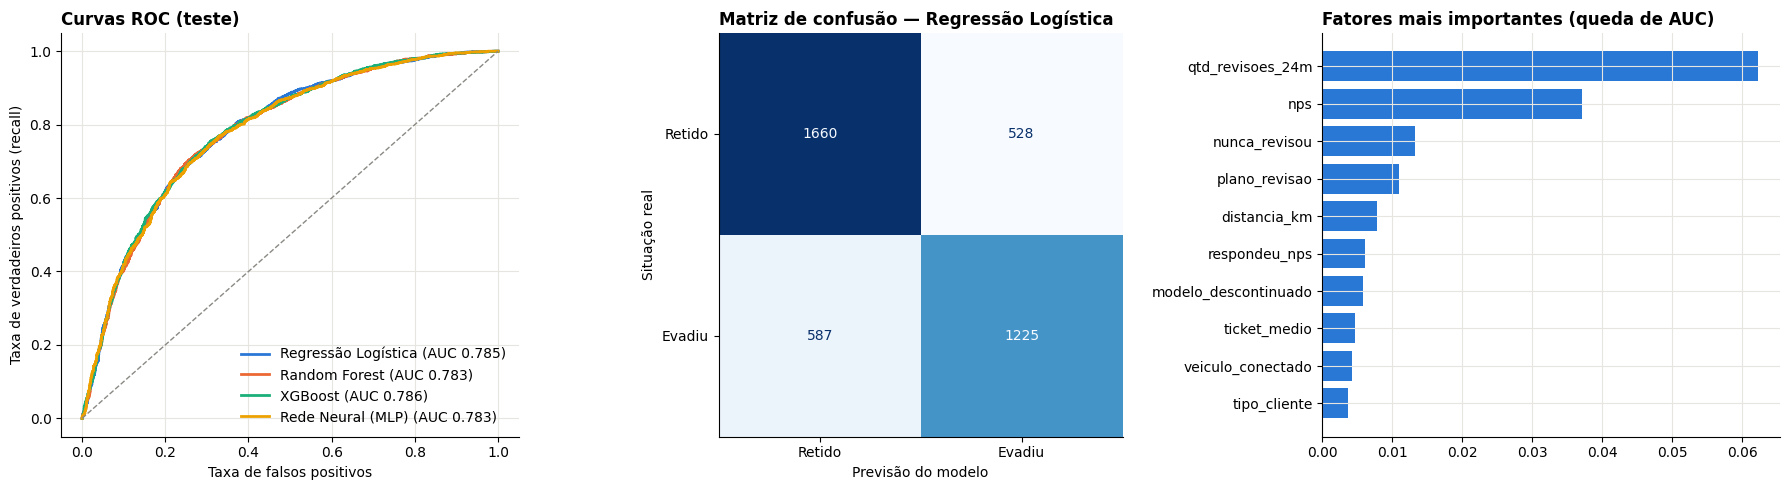

In [16]:
modelo_final = resultados[MELHOR].best_estimator_
importancia = permutation_importance(modelo_final, X_teste, y_teste, scoring='roc_auc', n_repeats=3, random_state=SEED)
importancia = pd.Series(importancia.importances_mean, index=X_teste.columns).sort_values()

fig, eixos = plt.subplots(1, 3, figsize=(18, 5))
for cor, (nome, p) in zip(CORES, probabilidades.items()):
    fpr, tpr, _ = roc_curve(y_teste, p)
    eixos[0].plot(fpr, tpr, color=cor, linewidth=2, label=f'{nome} (AUC {roc_auc_score(y_teste, p):.3f})')
eixos[0].plot([0, 1], [0, 1], '--', color='#8a8984', linewidth=1)
eixos[0].set_xlabel('Taxa de falsos positivos'); eixos[0].set_ylabel('Taxa de verdadeiros positivos (recall)')
eixos[0].set_title('Curvas ROC (teste)'); eixos[0].legend(loc='lower right', frameon=False)

ConfusionMatrixDisplay.from_predictions(y_teste, (probabilidades[MELHOR] >= 0.5).astype(int), ax=eixos[1],
                                        display_labels=['Retido', 'Evadiu'], cmap='Blues', colorbar=False)
eixos[1].set_xlabel('Previsão do modelo'); eixos[1].set_ylabel('Situação real')
eixos[1].set_title(f'Matriz de confusão — {MELHOR}'); eixos[1].grid(False)

eixos[2].barh(importancia.tail(10).index, importancia.tail(10).values, color=CORES[0])
eixos[2].set_title('Fatores mais importantes (queda de AUC)')
plt.tight_layout()
plt.show()

- **Matriz de confusão (4.000 veículos):** dos 1.812 que evadiram, 1.225 foram identificados (recall de 67,6%); dos 1.753 alertas, 69,9% estavam corretos.
- **Fatores:** `qtd_revisoes_24m` (queda de 0,06 na AUC) e `nps` (0,04) lideram, seguidos de `nunca_revisou`, `plano_revisao` e `distancia_km`. O relacionamento com a rede pesa mais do que as características do veículo.
- **Variáveis criadas:** `nunca_revisou` (3ª), `respondeu_nps` (6ª) e `modelo_descontinuado` (7ª) contribuíram; `em_garantia` e `km_por_mes` ficaram fora das 10 primeiras.
- **Limite da AUC:** parte da decisão do cliente depende de fatores ausentes dos dados, representados na base pelo engajamento oculto.

## 4.3 Explicabilidade e ponto de corte

Os pesos da Regressão Logística mostram a direção e a força de cada fator. A razão de chances indica por quanto a chance de evasão é multiplicada: 1,5 significa chance 50% maior; 0,7, chance 30% menor.

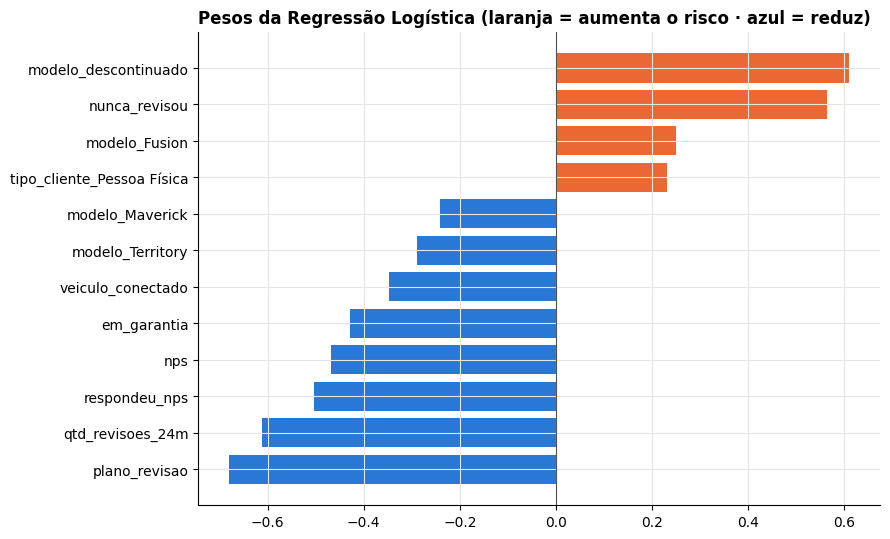

,peso,razão de chances
modelo_descontinuado,0.61,1.84
nunca_revisou,0.56,1.76
modelo_Fusion,0.25,1.29
tipo_cliente_Pessoa Física,0.23,1.26
modelo_Maverick,-0.24,0.79
modelo_Territory,-0.29,0.75
veiculo_conectado,-0.35,0.71
em_garantia,-0.43,0.65
nps,-0.47,0.63
respondeu_nps,-0.50,0.60


In [17]:
# Pesos da Regressão Logística treinada
regressao = resultados['Regressão Logística'].best_estimator_
prep = regressao.named_steps['prep']
nomes = NUM_LOG + NUM + BIN + list(prep.named_transformers_['cat'].get_feature_names_out(CAT))
pesos_rl = pd.Series(regressao.named_steps['modelo'].coef_[0], index=nomes)
principais = pesos_rl.reindex(pesos_rl.abs().sort_values(ascending=False).index).head(12).sort_values()

fig, eixo = plt.subplots(figsize=(9, 5.5))
eixo.barh(principais.index, principais.values, color=[CORES[1] if v > 0 else CORES[0] for v in principais.values])
eixo.axvline(0, color='#52514e', linewidth=0.8)
eixo.set_title('Pesos da Regressão Logística (laranja = aumenta o risco · azul = reduz)')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'peso': principais[::-1], 'razão de chances': np.exp(principais[::-1])}).round(2))

Aumentam o risco: modelo descontinuado (1,84) e nenhuma revisão recente (1,76). Reduzem: plano de revisão (0,51), mais revisões (0,54), resposta ao NPS (0,60), NPS alto (0,63), garantia (0,65) e conectividade (0,71). A garantia tem peso relevante, mas afeta só 3,1% da base e, por isso, pouco influi no desempenho geral. Com esses pesos, o consultor consegue justificar cada lead.

O **ponto de corte** é a probabilidade mínima para um veículo virar lead. Foram comparados três critérios, definidos no treino e avaliados no teste: o padrão (50%), o de maior F1 e o de capacidade, em que apenas os 20% de maior risco viram lead.

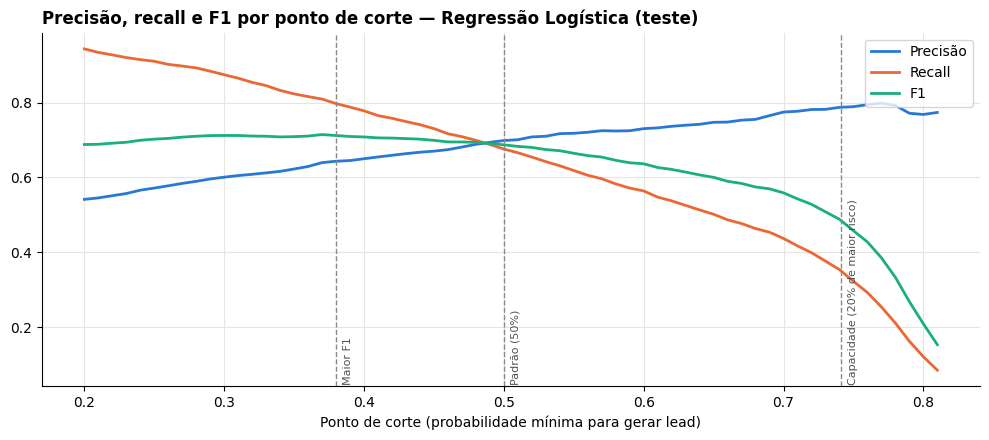

,Ponto de corte,Veículos sinalizados,Precisão,Recall,F1
Padrão (50%),0.500,1753,0.699,0.676,0.687
Maior F1,0.380,2246,0.643,0.797,0.712
Capacidade (20% de maior risco),0.741,805,0.788,0.350,0.485


In [18]:
from sklearn.model_selection import cross_val_predict

# Cortes definidos no treino (validação cruzada) e avaliados no teste
p_treino = cross_val_predict(resultados[MELHOR].best_estimator_, X_treino, y_treino, cv=3, method='predict_proba')[:, 1]
p_teste = probabilidades[MELHOR]
cortes = np.round(np.arange(0.20, 0.81, 0.01), 2)
f1_treino = pd.Series([f1_score(y_treino, (p_treino >= c).astype(int)) for c in cortes], index=cortes)
criterios = {'Padrão (50%)': 0.50, 'Maior F1': f1_treino.idxmax(), 'Capacidade (20% de maior risco)': np.quantile(p_treino, 0.80)}

curva = pd.DataFrame({
    'Precisão': [precision_score(y_teste, (p_teste >= c).astype(int), zero_division=0) for c in cortes],
    'Recall': [recall_score(y_teste, (p_teste >= c).astype(int)) for c in cortes],
    'F1': [f1_score(y_teste, (p_teste >= c).astype(int)) for c in cortes],
}, index=cortes)

fig, eixo = plt.subplots(figsize=(10, 4.5))
for cor, coluna in zip(CORES, curva.columns):
    eixo.plot(curva.index, curva[coluna], color=cor, linewidth=2, label=coluna)
for nome, corte in criterios.items():
    eixo.axvline(corte, color='#8a8984', linestyle='--', linewidth=1)
    eixo.text(corte + 0.005, 0.05, nome, rotation=90, fontsize=8, color='#52514e')
eixo.set_xlabel('Ponto de corte (probabilidade mínima para gerar lead)')
eixo.set_title(f'Precisão, recall e F1 por ponto de corte — {MELHOR} (teste)')
eixo.legend(loc='upper right')
plt.tight_layout()
plt.show()

resumo_cortes = pd.DataFrame({nome: {
    'Ponto de corte': corte,
    'Veículos sinalizados': (p_teste >= corte).sum(),
    'Precisão': precision_score(y_teste, (p_teste >= corte).astype(int)),
    'Recall': recall_score(y_teste, (p_teste >= corte).astype(int)),
    'F1': f1_score(y_teste, (p_teste >= corte).astype(int)),
} for nome, corte in criterios.items()}).T
resumo_cortes['Veículos sinalizados'] = resumo_cortes['Veículos sinalizados'].astype(int)
display(resumo_cortes.round(3))

| Critério | Corte | Veículos sinalizados | Precisão | Recall |
|---|---|---|---|---|
| Padrão | 50% | 1.753 | 69,9% | 67,6% |
| Maior F1 | 38% | 2.246 | 64,3% | 79,7% |
| Capacidade (20% de maior risco) | 74,1% | 805 | 78,8% | 35,0% |

Recomenda-se o corte de 38% para ações de baixo custo em escala, como lembretes pelo FordPass, pois deixa escapar menos clientes. Para contatos individuais, o corte por capacidade faz com que quase 4 de cada 5 contatos atinjam clientes que realmente sairiam da rede.

# 5. Conclusão

> **Critérios atendidos:** modelo selecionado · justificativa · principais resultados · uso na aplicação e deploy · melhorias

A **Regressão Logística** foi selecionada: teve a maior AUC na validação cruzada (0,795), manteve o desempenho no teste (0,785) com o menor sobreajuste, e os modelos mais complexos não trouxeram ganho. Por ser simples, as suas previsões podem ser explicadas ao consultor pelos pesos das variáveis.

Na prática, contatar os 20% de maior risco alcança 34,8% das evasões, 1,7 vez mais do que uma escolha aleatória, e o corte de 38% identifica 79,7% delas. A evasão se concentra em veículos antigos e de modelos descontinuados e diminui com revisões frequentes, satisfação e planos de revisão. Ações de relacionamento são, portanto, o caminho para elevar o VIN Share e as chances de recompra.

## 5.1 Deploy e melhorias

O pipeline salvo é disponibilizado por uma **API REST** (por exemplo, com FastAPI), consumida pela aplicação do projeto em dois modos: **lote diário**, que gera a lista de leads de cada concessionária com a ação sugerida (lembrete, recall ou plano de revisões) e ofertas de recompra para clientes fiéis; e **consulta individual** durante o atendimento. O código abaixo salva o modelo e avalia um veículo de exemplo, um Ka de 6 anos sem revisões recentes e com recall pendente: o risco estimado é de 72,3%, o que gera um lead.

In [19]:
joblib.dump(modelo_final, 'modelo_vinshare.joblib')
modelo_carregado = joblib.load('modelo_vinshare.joblib')

novo_veiculo = pd.DataFrame([{
    'km_por_mes': 1400, 'distancia_km': 35, 'ticket_medio': np.nan, 'idade_meses': 70, 'qtd_revisoes_24m': 0,
    'meses_ult_servico': 70, 'nps': np.nan, 'em_garantia': 0, 'nunca_revisou': 1, 'respondeu_nps': 0,
    'modelo_descontinuado': 1, 'veiculo_conectado': 0, 'plano_revisao': 0, 'recall_pendente': 1,
    'modelo': 'Ka', 'regiao': 'Nordeste', 'tipo_cliente': 'Pessoa Física',
}])[X.columns]
risco = modelo_carregado.predict_proba(novo_veiculo)[0, 1]
acao = 'gerar lead de serviço (convite para recall + revisão)' if risco >= 0.5 else 'manter relacionamento padrão'
print(f'Probabilidade de evasão: {risco:.1%} → {acao}')

Probabilidade de evasão: 72.3% → gerar lead de serviço (convite para recall + revisão)


**Melhorias futuras:** usar dados reais da Ford (concessionárias, garantia e telemetria FordPass) e reavaliar os modelos não lineares; validar os pontos de corte em campo com testes A/B; explicar cada previsão individualmente; e expandir a solução para outros países da América do Sul.